# House Prices — Năm mô hình trên năm bộ đặc trưng sau lọc ngoại lệ

So sánh DummyRegressor, Ridge, Random Forest, Lasso và SVR trước và sau lọc. Giữ siêu tham số cố định và dùng cùng 5 fold (seed 42). Quy tắc chọn sau khi xem dữ liệu gốc đánh dấu GrLivArea > 4000 và SalePrice < 200000. Chỉ lọc trong phần huấn luyện, giữ đủ 1.460 căn để tính điểm validation. Đây là phân tích độ nhạy trên bộ dữ liệu hiện tại.

## Tham số cố định

In [1]:
EXPERIMENT_NAME = "15-11-2026_5model_5bo_outlier_phuc"
RANDOM_STATE = 42
N_SPLITS = 5

MODEL_PARAMS = {
    "DummyRegressor": {"strategy": "mean"},
    "Ridge": {"alpha": 1.0, "solver": "lsqr"},
    "Random Forest": {"n_estimators": 200, "min_samples_leaf": 2, "random_state": RANDOM_STATE},
    "Lasso": {"alpha": 0.001, "max_iter": 10000},
    "XGBoost": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                "random_state": RANDOM_STATE, "n_jobs": 2},
    "SVR": {"C": 10.0, "epsilon": 0.05, "gamma": "scale"},
}
MODEL_PARAMS.pop("XGBoost")
AREA_LIMIT = 4000
PRICE_LIMIT = 200000

## Import và kiểm tra kernel

In [2]:
from itertools import combinations
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor
from src.models import make_dummy, make_ridge, make_random_forest
from src.model import make_lasso, make_svr

## Dữ liệu và tạo đặc trưng

- `TotalSF` cộng diện tích tầng hầm, tầng 1 và tầng 2.
- `TotalBath` cộng phòng tắm đầy đủ ở phần trên mặt đất và tầng hầm. Mỗi nửa phòng tắm tính 0,5.
- `AgeAtSale` lấy năm bán trừ năm xây.

Các phép tính dùng dữ liệu của từng căn nhà. Pipeline điền thiếu, chuẩn hóa và mã hóa được fit trên phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

formulas = {
    "TotalSF": "TotalBsmtSF + 1stFlrSF + 2ndFlrSF",
    "TotalBath": "FullBath + BsmtFullBath + 0.5 * (HalfBath + BsmtHalfBath)",
    "AgeAtSale": "YrSold - YearBuilt",
}
X_extra = X.assign(
    TotalSF=X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"],
    TotalBath=X["FullBath"] + X["BsmtFullBath"] + 0.5 * (X["HalfBath"] + X["BsmtHalfBath"]),
    AgeAtSale=X["YrSold"] - X["YearBuilt"],
)
assert X_extra.shape[1] == 82
display(X_extra[list(formulas)].describe().round(2))

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y, "fold": 0})
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold
baseline_dir = (project / "experiments" / "14-11-2026_6model_79_phuc"
                / "outputs" / "20261114_224507_500186")
baseline = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline[[ID, "fold"]])
np.testing.assert_allclose(y, baseline["ln_SalePrice"])
suspect = train["GrLivArea"].gt(AREA_LIMIT) & prices.lt(PRICE_LIMIT)
suspected_outliers = train.loc[suspect, [ID, "GrLivArea", TARGET]].copy()
suspected_outliers["validation_fold"] = predictions.loc[suspect, "fold"]
display(suspected_outliers)



,TotalSF,TotalBath,AgeAtSale
count,1460.00,1460.00,1460.00
mean,2567.05,2.21,36.55
std,821.71,0.79,30.25
min,334.00,1.00,0.00
25%,2009.50,2.00,8.00
50%,2474.00,2.00,35.00
75%,3004.00,2.50,54.00
max,11752.00,6.00,136.00


,Id,GrLivArea,SalePrice,validation_fold
523,524,4676,184750,3
1298,1299,5642,160000,3


## Huấn luyện và so sánh

In [4]:
factories = {
    "DummyRegressor": make_dummy, "Ridge": make_ridge,
    "Random Forest": make_random_forest, "Lasso": make_lasso, "SVR": make_svr,
}
metric_rows = []
warning_rows = []
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
variants = {"79_goc": X}
feature_pairs = list(combinations(formulas, 2))
for pair in feature_pairs:
    variants[" + ".join(pair)] = X_extra.loc[:, [*X.columns, *pair]]

variants["82_ca_ba"] = X_extra

for policy in ("keep", "filter_train"):
    for model, factory in factories.items():
        for variant, features in variants.items():
            pipeline = make_pipeline(make_preprocessor(features), factory(**MODEL_PARAMS[model]))
            scores = []
            started = perf_counter()
            for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
                kept = fit_idx if policy == "keep" else fit_idx[~suspect.iloc[fit_idx].to_numpy()]
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    fitted = clone(pipeline).fit(features.iloc[kept], y.iloc[kept])
                    predicted = fitted.predict(features.iloc[valid_idx])
                predictions.loc[valid_idx, f"{model} | {variant} | {policy}"] = predicted
                scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))
                for item in caught:
                    warning_rows.append({"model": model, "variant": variant, "policy": policy, "fold": fold,
                                         "category": item.category.__name__, "message": str(item.message)})
            metric_rows.append({
                "model": model, "variant": variant, "policy": policy, "features": features.shape[1],
                **dict(zip(fold_columns, scores)),
                "rmse_log_mean": np.mean(scores), "rmse_log_std": np.std(scores, ddof=1),
                "elapsed_seconds": perf_counter() - started,
            })


results = pd.DataFrame(metric_rows).set_index(["model", "variant", "policy"])
before = results.xs("keep", level="policy")
after = results.xs("filter_train", level="policy")
comparison = after[fold_columns] - before[fold_columns]
comparison["rmse_before_filter"] = before["rmse_log_mean"]
comparison["rmse_after_filter"] = after["rmse_log_mean"]
comparison["delta_mean"] = comparison["rmse_after_filter"] - comparison["rmse_before_filter"]
comparison["folds_improved"] = (comparison[fold_columns] < -1e-12).sum(axis=1)
assert len(predictions) == 1460 and predictions.notna().all().all()
display(comparison.round(5))

fold1  ...  folds_improved
model          variant                         ...                
DummyRegressor 79_goc                -0.00000  ...               2
               TotalSF + TotalBath   -0.00000  ...               2
               TotalSF + AgeAtSale   -0.00000  ...               2
               TotalBath + AgeAtSale -0.00000  ...               2
               82_ca_ba              -0.00000  ...               2
Ridge          79_goc                -0.00748  ...               4
               TotalSF + TotalBath   -0.00746  ...               4
               TotalSF + AgeAtSale   -0.00760  ...               4
               TotalBath + AgeAtSale -0.00760  ...               4
               82_ca_ba              -0.00752  ...               4
Random Forest  79_goc                -0.00066  ...               2
               TotalSF + TotalBath    0.00092  ...               1
               TotalSF + AgeAtSale   -0.00107  ...               2
               TotalBath + AgeAtSale -0.00112  ...               3
               82_ca_ba               0.00000  ...               1
Lasso          79_goc                -0.00664  ...               4
               TotalSF + TotalBath   -0.00674  ...               4
               TotalSF + AgeAtSale   -0.00670  ...               4
               TotalBath + AgeAtSale -0.00662  ...               4
               82_ca_ba              -0.00672  ...               4
SVR            79_goc                -0.00064  ...               2
               TotalSF + TotalBath   -0.00059  ...               2
               TotalSF + AgeAtSale   -0.00058  ...               2
               TotalBath + AgeAtSale -0.00073  ...               2
               82_ca_ba              -0.00060  ...               2

[25 rows x 9 columns]

## Biểu đồ và nhận xét

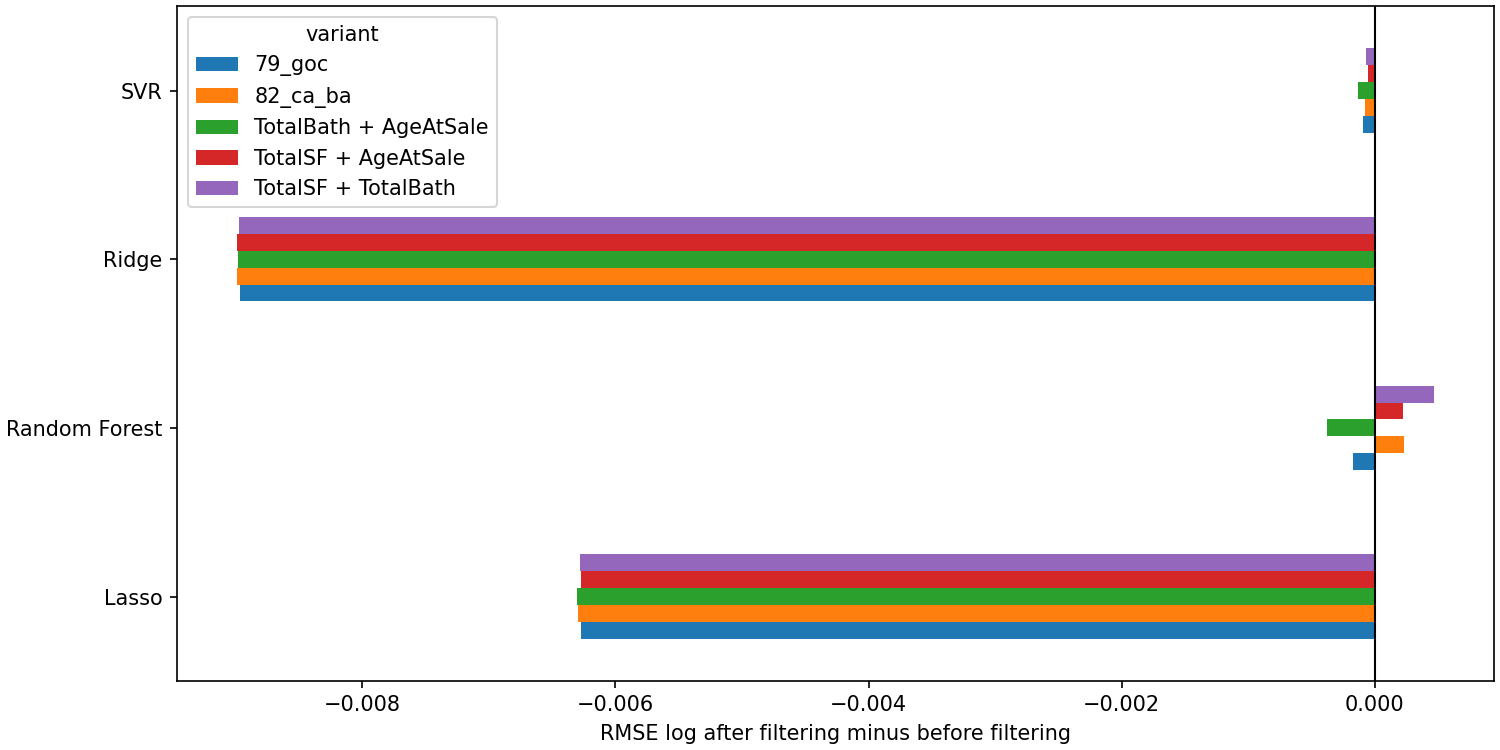

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
changes = comparison["delta_mean"].unstack().drop(index="DummyRegressor")
changes.plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="RMSE log after filtering minus before filtering", ylabel="")
plt.show()

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv")
comparison.to_csv(run_dir / "comparison_outliers.csv", index_label=["model", "variant"])
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
pd.DataFrame(warning_rows, columns=["model", "variant", "policy", "fold", "category", "message"]).to_csv(
    run_dir / "validation_warnings.csv", index=False
)
config = {
    "dataset": "data/raw/train.csv", "target_transform": "natural log",
    "baseline": str(baseline_dir.relative_to(project)), "feature_formulas": formulas, "feature_pairs": feature_pairs,
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "outlier_rule": {"GrLivArea_gt": AREA_LIMIT, "SalePrice_lt": PRICE_LIMIT, "scope": "fold train only"},
    "model_params": MODEL_PARAMS,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "outlier_comparison.png", dpi=150)
print(run_dir.relative_to(project))
suspected_outliers.to_csv(run_dir / "suspected_outliers.csv", index=False)


experiments\15-11-2026_5model_5bo_outlier_phuc\outputs\20261115_110212_593276
